# GlobalForms metric pilot

This notebook walks through two questions for each selected form. **Track A** asks how well a candidate recovers the form from the blank page. **Track B** asks whether a submitted completion uses the facts supplied in a scenario.

The saved walkthrough shows every bundled fixture. To focus on one in Jupyter, set `FIXTURE` in the next cell to a fixture name or a path to its `review.json`, then **Restart Kernel and Run All Cells**. Use `"all"` to compare them again. The locker model example replays a cached prediction locally.

A native annotation manifest opens its own page overlays, field ledger and recorded omission scores directly below the selector. The Track A and B sections use metric-format bundles.

To preview the blank Aetna form from the issuer, set `FIXTURE = fetch_aetna_pdf()` below. The first call stores the verified PDF in the per-user cache. Set `GLOBALFORMS_CACHE_DIR` in your environment or local `.env` to choose the location. To see field overlays and omission scores, select your private annotation manifest.

In [1]:
import os
from pathlib import Path

from IPython.display import IFrame, Markdown, display

from globalforms.annotation_review import (
    OmissionAnnotation, load_notebook_fixture, notebook_report_url, write_annotation_review,
)
from globalforms.fixtures import read_page, review_manifests
from globalforms.source_pdf import fetch_aetna_pdf, write_pdf_preview

FIXTURE = os.environ.get("GLOBALFORMS_FIXTURE", "all")

reviews = {}
for path in review_manifests(FIXTURE):
    name = path.resolve().parent.name
    output_dir = Path("output") / name
    if path.suffix.lower() == ".pdf":
        report = write_pdf_preview(path, output_dir / f"{path.stem}-preview.html")
    else:
        review = load_notebook_fixture(path)
        if isinstance(review, OmissionAnnotation):
            report = write_annotation_review(review, output_dir / "annotation.html")
        else:
            reviews[name] = review
            print(f"{name} · page {review.page} · {len(review.track_a)} Track A · {len(review.track_b)} Track B")
            continue
    url = notebook_report_url(report)
    display(Markdown(f"[Open the local review]({url})"))
    display(IFrame(src=url, width="100%", height=820))

incident · page 1 · 5 Track A · 5 Track B
length · page 1 · 1 Track A · 0 Track B
locker · page 2 · 2 Track A · 2 Track B


## Read the reference form

The colors group the serialized spec as in the paper. Fields are blue, answer regions green, role declarations purple, rules amber and validations red. Expand the comparison under a prediction to see its changed entries alongside the reference. The comparison uses the IDs as supplied.

`regions` locate where an answer goes. `evidenceIds` cite items in `evidence`, each a page and bounding box for source material such as a label, heading or instruction. The validator checks that a cited ID exists. Track A scores answer-region geometry, and Track B can use that geometry to align recovered fields. Neither track scores the location or relevance of the cited evidence.

### incident · page 1

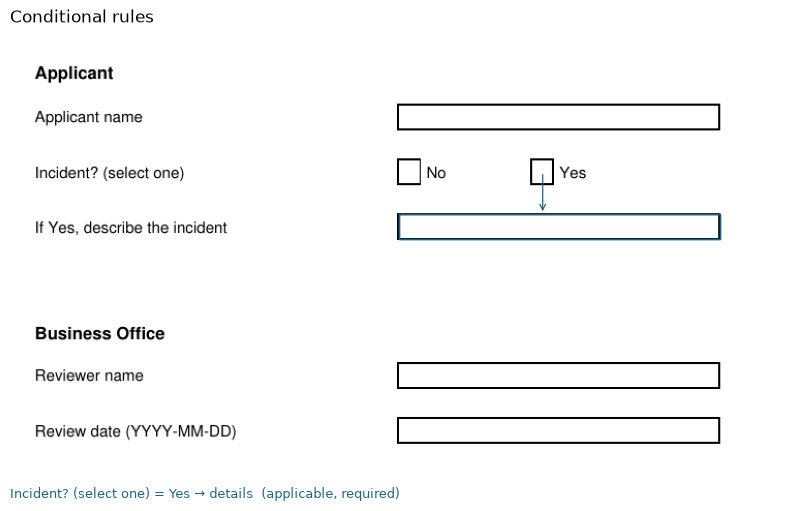

Spec group,FormSpec
■ schemaVersion,"""pilot-2"""
■ sections,"{ ""applicant"": {""title"": ""Applicant"", ""evidenceIds"": [""applicant_heading""]}, ""office"": { ""title"": ""Business Office"", ""evidenceIds"": [""office_heading""], ""role"": ""Business Office"" } }"
■ fields,"{ ""name"": { ""label"": ""Applicant name"", ""section"": ""applicant"", ""evidenceIds"": [""name""], ""regions"": [""name_0""], ""type"": ""text"", ""options"": {} }, ""reviewer"": { ""label"": ""Reviewer name"", ""section"": ""office"", ""evidenceIds"": [""reviewer""], ""regions"": [""reviewer_0""], ""type"": ""text"", ""options"": {} }, ""review_date"": { ""label"": ""Review date (YYYY-MM-DD)"", ""section"": ""office"", ""evidenceIds"": [""review_date""], ""regions"": [""review_date_0""], ""type"": ""date"", ""options"": {} }, ""incident"": { ""label"": ""Incident? (select one)"", ""section"": ""applicant"", ""evidenceIds"": [""incident""], ""regions"": [""incident_0"", ""incident_1""], ""type"": ""choice"", ""options"": {""No"": ""incident_0"", ""Yes"": ""incident_1""}, ""cardinality"": [1, 1] }, ""details"": { ""label"": ""If Yes, describe the incident"", ""section"": ""applicant"", ""evidenceIds"": [""details""], ""regions"": [""details_0""], ""type"": ""text"", ""options"": {} } }"
■ regions,"{ ""name_0"": {""page"": 1, ""bbox"": [280.0, 85.0, 205.0, 16.0]}, ""reviewer_0"": {""page"": 1, ""bbox"": [280.0, 250.0, 205.0, 16.0]}, ""review_date_0"": {""page"": 1, ""bbox"": [280.0, 285.0, 205.0, 16.0]}, ""incident_0"": {""page"": 1, ""bbox"": [280.0, 120.0, 14.0, 16.0]}, ""incident_1"": {""page"": 1, ""bbox"": [365.0, 120.0, 14.0, 16.0]}, ""details_0"": {""page"": 1, ""bbox"": [280.0, 155.0, 205.0, 16.0]} }"
■ rules,"[ { ""effect"": ""applicable"", ""controller"": ""incident"", ""op"": ""eq"", ""option"": ""Yes"", ""fields"": [""details""], ""evidenceIds"": [""details""] }, { ""effect"": ""required"", ""controller"": ""incident"", ""op"": ""eq"", ""option"": ""Yes"", ""fields"": [""details""], ""evidenceIds"": [""details""] } ]"
■ validations,"[ { ""fields"": [""review_date""], ""evidenceIds"": [""review_date""], ""kind"": ""date_format"", ""format"": ""YYYY-MM-DD"" } ]"
■ evidence,"{ ""name"": {""page"": 1, ""bbox"": [48.0, 85.0, 215.0, 16.0]}, ""applicant_heading"": {""page"": 1, ""bbox"": [48.0, 61.102, 50.116, 10.175]}, ""office_heading"": {""page"": 1, ""bbox"": [48.0, 227.102, 83.138, 10.175]}, ""reviewer"": {""page"": 1, ""bbox"": [48.0, 250.0, 215.0, 16.0]}, ""review_date"": {""page"": 1, ""bbox"": [48.0, 285.0, 215.0, 16.0]}, ""incident"": {""page"": 1, ""bbox"": [48.0, 120.0, 215.0, 16.0]}, ""details"": {""page"": 1, ""bbox"": [48.0, 155.0, 215.0, 16.0]} }"


### length · page 1

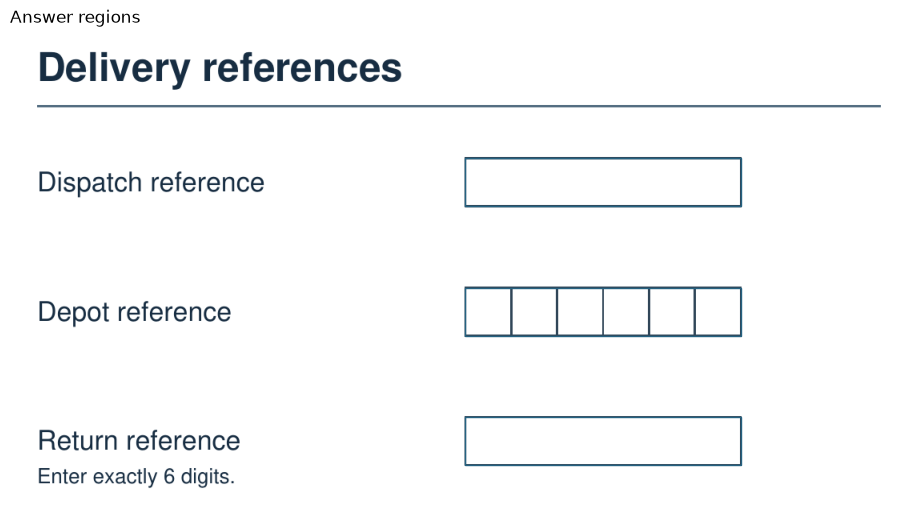

Spec group,FormSpec
■ schemaVersion,"""pilot-2"""
■ sections,{}
■ fields,"{ ""plain"": { ""label"": ""Dispatch reference"", ""section"": null, ""evidenceIds"": [""plain_label""], ""regions"": [""plain_box""], ""type"": ""text"", ""options"": {} }, ""cells"": { ""label"": ""Depot reference"", ""section"": null, ""evidenceIds"": [""cells_label""], ""regions"": [""cells_box""], ""type"": ""text"", ""options"": {} }, ""digits"": { ""label"": ""Return reference"", ""section"": null, ""evidenceIds"": [""digits_label""], ""regions"": [""digits_box""], ""type"": ""text"", ""options"": {} } }"
■ regions,"{ ""plain_box"": {""page"": 1, ""bbox"": [233.0, 75.0, 132.0, 23.0]}, ""cells_box"": {""page"": 1, ""bbox"": [233.0, 137.0, 132.0, 23.0]}, ""digits_box"": {""page"": 1, ""bbox"": [233.0, 199.0, 132.0, 23.0]} }"
■ rules,[]
■ validations,"[ { ""fields"": [""cells""], ""evidenceIds"": [""six_cells""], ""kind"": ""length"", ""max"": 6 }, { ""fields"": [""digits""], ""evidenceIds"": [""digits_instruction""], ""kind"": ""length"", ""min"": 6, ""max"": 6 }, { ""fields"": [""digits""], ""evidenceIds"": [""digits_instruction""], ""kind"": ""character_set"", ""alphabet"": ""ascii_digits"" } ]"
■ evidence,"{ ""plain_label"": {""page"": 1, ""bbox"": [28.0, 79.0, 109.1, 15.0]}, ""cells_label"": {""page"": 1, ""bbox"": [28.0, 141.0, 93.2, 15.0]}, ""six_cells"": {""page"": 1, ""bbox"": [233.0, 137.0, 132.0, 23.0]}, ""digits_label"": {""page"": 1, ""bbox"": [28.0, 203.0, 97.5, 15.0]}, ""digits_instruction"": {""page"": 1, ""bbox"": [28.0, 221.0, 95.0, 13.0]} }"


### locker · page 2

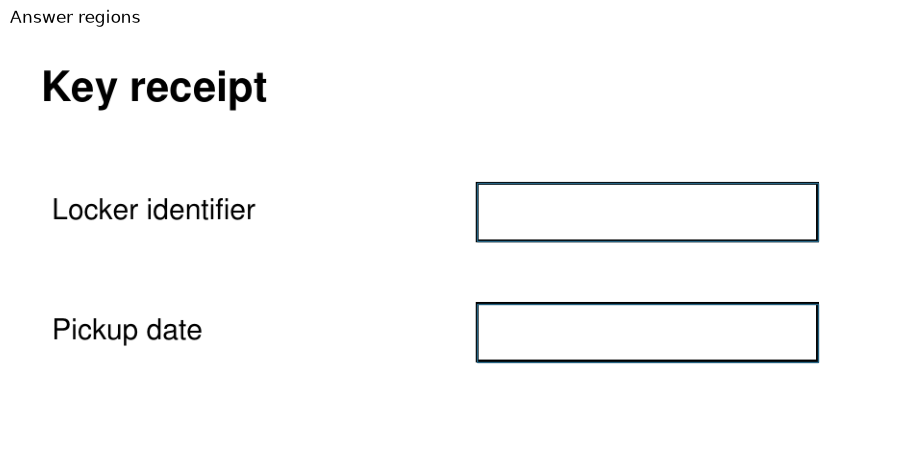

Spec group,FormSpec
■ schemaVersion,"""pilot-2"""
■ sections,"{ ""receipt"": { ""title"": ""Key receipt"", ""evidenceIds"": [""heading""], ""role"": ""Custodian"" } }"
■ fields,"{ ""locker"": { ""label"": ""Locker identifier"", ""section"": ""receipt"", ""evidenceIds"": [""locker_label""], ""regions"": [""locker_box""], ""type"": ""text"", ""options"": {} }, ""pickup"": { ""label"": ""Pickup date"", ""section"": ""receipt"", ""evidenceIds"": [""date_label""], ""regions"": [""date_box""], ""type"": ""date"", ""options"": {} } }"
■ regions,"{ ""locker_box"": {""page"": 2, ""bbox"": [190.0, 76.0, 130.0, 22.0]}, ""date_box"": {""page"": 2, ""bbox"": [190.0, 122.0, 130.0, 22.0]} }"
■ rules,[]
■ validations,[]
■ evidence,"{ ""heading"": {""page"": 2, ""bbox"": [24.0, 33.0, 85.0, 16.0]}, ""locker_label"": {""page"": 2, ""bbox"": [28.0, 82.0, 80.0, 11.0]}, ""date_label"": {""page"": 2, ""bbox"": [28.0, 128.0, 60.0, 11.0]} }"


In [2]:
from globalforms.notebook_review import show_reference_page

pages = {name: read_page(review) for name, review in reviews.items()}
for name, review in reviews.items():
    display(Markdown(f"### {name} · page {review.page}"))
    show_reference_page(review, *pages[name])
    display(review.reference)

## Document constraints

The table shows what each field adds to its type. Evidence IDs locate the printed instruction or layout supporting each constraint. Example values, when supplied by the fixture, exercise only these additional checks.

In [3]:
from globalforms.notebook_review import show_constraints

for name, review in reviews.items():
    display(Markdown(f"### {name}"))
    show_constraints(review)

### incident

Field,Constraint,Evidence
Applicant name,None,
Reviewer name,None,
Review date (YYYY-MM-DD),YYYY-MM-DD,review_date
Incident? (select one),None,
"If Yes, describe the incident",None,


### length

Field,Constraint,Evidence,12,ABCDEF,001234,1234567
Dispatch reference,None,,Pass,Pass,Pass,Pass
Depot reference,≤ 6 chars,six_cells,Pass,Pass,Pass,Fail
Return reference,"exactly 6 chars, digits 0–9",digits_instruction,Fail,Fail,Pass,Fail


### locker

Field,Constraint,Evidence
Locker identifier,None,
Pickup date,None,


## Conditional effects in the reference

Each rule shows what its controller implies for the target. Applicability determines whether the field applies. Requiredness determines whether an active field needs an answer for submission. Track B can still credit an omission when the scenario gives no answer.

In [4]:
from globalforms.notebook_review import show_rule_effects

for name, review in reviews.items():
    display(Markdown(f"### {name}"))
    show_rule_effects(review.reference)

### incident

Incident? (select one) → If Yes, describe the incident (applicable)
  No → inactive
  Yes → active
  Unanswered → unresolved
Incident? (select one) → If Yes, describe the incident (required)
  No → no requirement from this rule
  Yes → required when active
  Unanswered → unresolved


### length

The reference declares no conditional rules.


### locker

The reference declares no conditional rules.


## Track A on the source PDF

Each pair compares a candidate and its reference on the same source page. For a cached model prediction, dashed outlines on the prediction panel show the reference boxes. The tables give overlap for matched regions and Track A scores for the whole form. Scores below each pair include downstream effects of the evaluator’s field matching. In the section comparison, each outlined heading shares a color with its direct members’ answer regions. An unassigned field stays unshaded. Roles use the field declaration first, then the nearest section with a role, then the fixture default. A role label marked “(default)” identifies a field that uses the fallback.

In the error matrix below each fixture, a 1 means the component has at least one false positive or false negative. A single planted error can affect multiple rows through field alignment. The first five rows are ranked components. The remaining rows are diagnostics.

### incident · Track A

Region coverage: reference 0%, prediction 0%


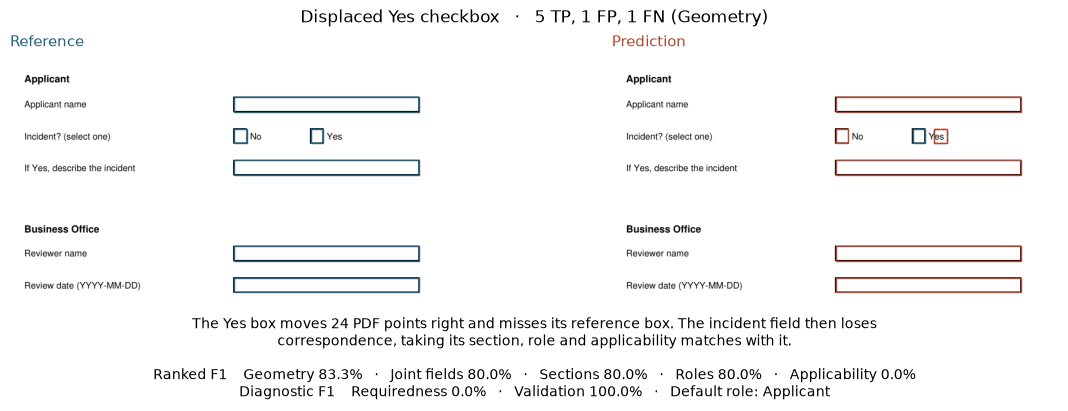

Spec group,Reference (GT),Prediction
■ regions,"{ ""incident_1"": {""page"": 1, ""bbox"": [365.0, 120.0, 14.0, 16.0]} }","{ ""incident_1"": {""page"": 1, ""bbox"": [389.0, 120.0, 14.0, 16.0]} }"


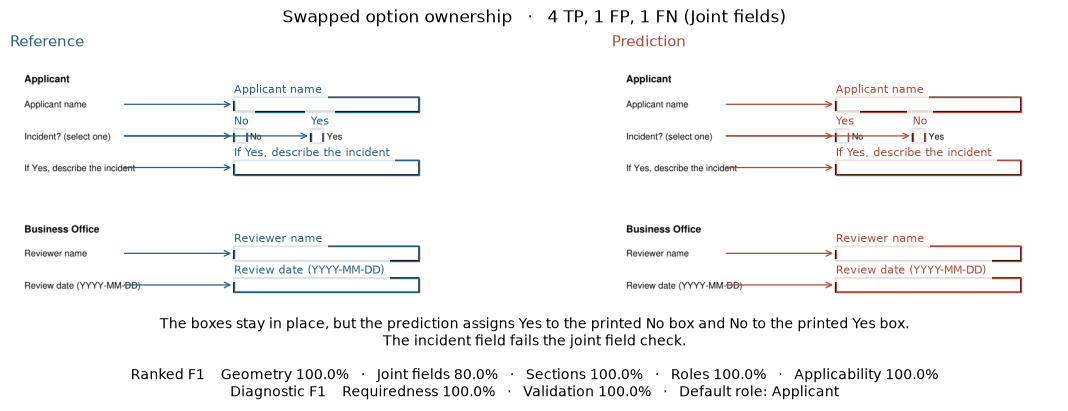

Spec group,Reference (GT),Prediction
■ fields,"{ ""incident"": { ""label"": ""Incident? (select one)"", ""section"": ""applicant"", ""evidenceIds"": [""incident""], ""regions"": [""incident_0"", ""incident_1""], ""type"": ""choice"", ""options"": {""No"": ""incident_0"", ""Yes"": ""incident_1""}, ""cardinality"": [1, 1] } }","{ ""incident"": { ""label"": ""Incident? (select one)"", ""section"": ""applicant"", ""evidenceIds"": [""incident""], ""regions"": [""incident_0"", ""incident_1""], ""type"": ""choice"", ""options"": {""Yes"": ""incident_0"", ""No"": ""incident_1""}, ""cardinality"": [1, 1] } }"


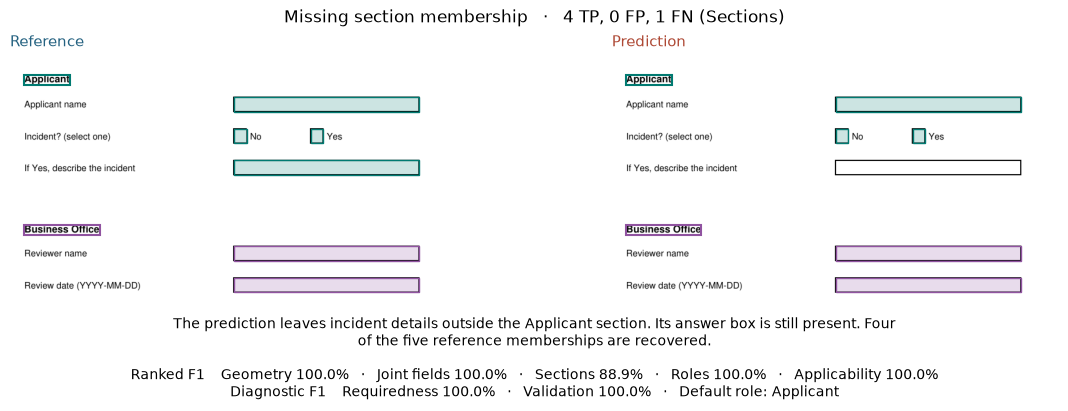

Spec group,Reference (GT),Prediction
■ fields,"{ ""details"": { ""label"": ""If Yes, describe the incident"", ""section"": ""applicant"", ""evidenceIds"": [""details""], ""regions"": [""details_0""], ""type"": ""text"", ""options"": {} } }","{ ""details"": { ""label"": ""If Yes, describe the incident"", ""section"": null, ""evidenceIds"": [""details""], ""regions"": [""details_0""], ""type"": ""text"", ""options"": {} } }"


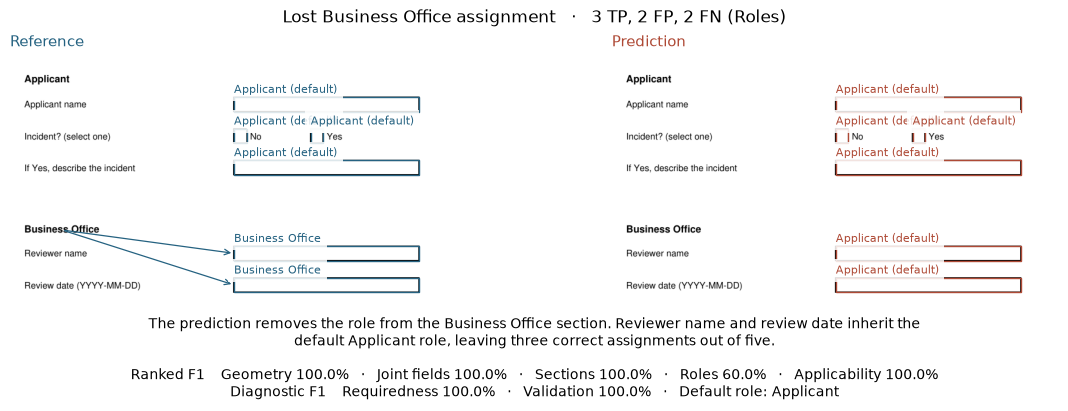

Spec group,Reference (GT),Prediction
■ sections,"{ ""office"": { ""title"": ""Business Office"", ""evidenceIds"": [""office_heading""], ""role"": ""Business Office"" } }","{ ""office"": {""title"": ""Business Office"", ""evidenceIds"": [""office_heading""]} }"


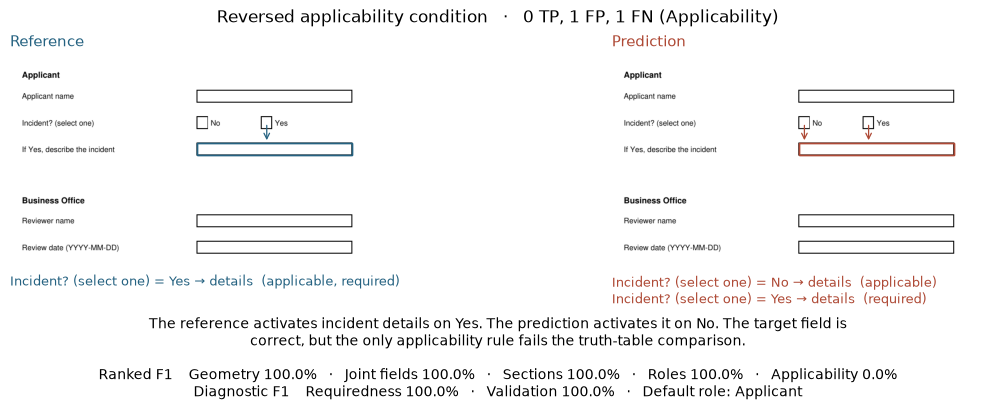

Spec group,Reference (GT),Prediction
■ rules,"[ { ""effect"": ""applicable"", ""controller"": ""incident"", ""op"": ""eq"", ""option"": ""Yes"", ""fields"": [""details""], ""evidenceIds"": [""details""] }, { ""effect"": ""required"", ""controller"": ""incident"", ""op"": ""eq"", ""option"": ""Yes"", ""fields"": [""details""], ""evidenceIds"": [""details""] } ]","[ { ""effect"": ""applicable"", ""controller"": ""incident"", ""op"": ""eq"", ""option"": ""No"", ""fields"": [""details""], ""evidenceIds"": [""details""] }, { ""effect"": ""required"", ""controller"": ""incident"", ""op"": ""eq"", ""option"": ""Yes"", ""fields"": [""details""], ""evidenceIds"": [""details""] } ]"


**Track A error matrix**

| Flag | Displaced Yes checkbox | Swapped option ownership | Missing section membership | Lost Business Office assignment | Reversed applicability condition |
| --- | --- | --- | --- | --- | --- |
| Geometry | 1 | 0 | 0 | 0 | 0 |
| Joint fields | 1 | 1 | 0 | 0 | 0 |
| Sections | 1 | 0 | 1 | 0 | 0 |
| Roles | 1 | 0 | 0 | 1 | 0 |
| Applicability | 1 | 0 | 0 | 0 | 1 |
| Field type | 1 | 0 | 0 | 0 | 0 |
| Field label | 1 | 0 | 0 | 0 | 0 |
| Option ownership | 1 | 1 | 0 | 0 | 0 |
| Cardinality | 1 | 0 | 0 | 0 | 0 |
| Requiredness | 1 | 0 | 0 | 0 | 0 |
| Validation | 0 | 0 | 0 | 0 | 0 |

### length · Track A

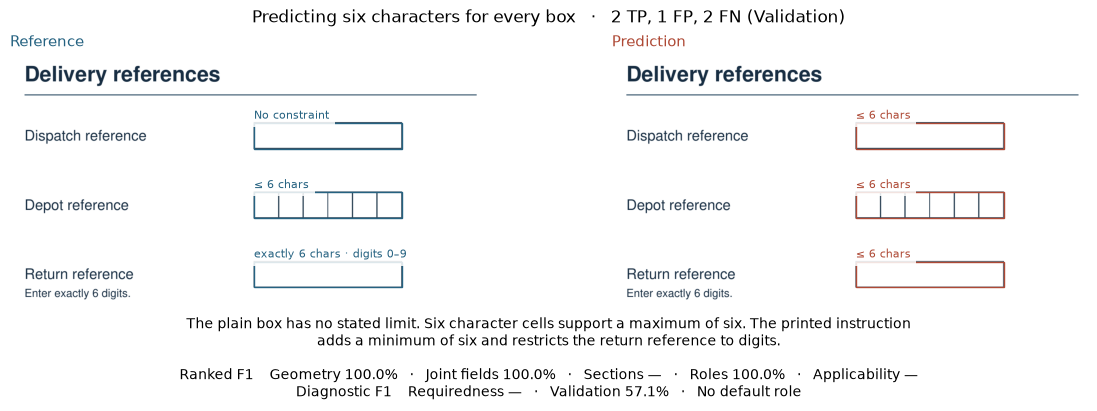

Spec group,Reference (GT),Prediction
■ validations,"[ { ""fields"": [""cells""], ""evidenceIds"": [""six_cells""], ""kind"": ""length"", ""max"": 6 }, { ""fields"": [""digits""], ""evidenceIds"": [""digits_instruction""], ""kind"": ""length"", ""min"": 6, ""max"": 6 }, { ""fields"": [""digits""], ""evidenceIds"": [""digits_instruction""], ""kind"": ""character_set"", ""alphabet"": ""ascii_digits"" } ]","[ { ""fields"": [""plain""], ""evidenceIds"": [""plain_label""], ""kind"": ""length"", ""max"": 6 }, { ""fields"": [""cells""], ""evidenceIds"": [""six_cells""], ""kind"": ""length"", ""max"": 6 }, { ""fields"": [""digits""], ""evidenceIds"": [""digits_instruction""], ""kind"": ""length"", ""max"": 6 } ]"


**Track A error matrix**

| Flag | Predicting six characters for every box |
| --- | --- |
| Geometry | 0 |
| Joint fields | 0 |
| Sections | 0 |
| Roles | 0 |
| Applicability | 0 |
| Field type | 0 |
| Field label | 0 |
| Option ownership | 0 |
| Cardinality | 0 |
| Requiredness | 0 |
| Validation | 1 |

### locker · Track A

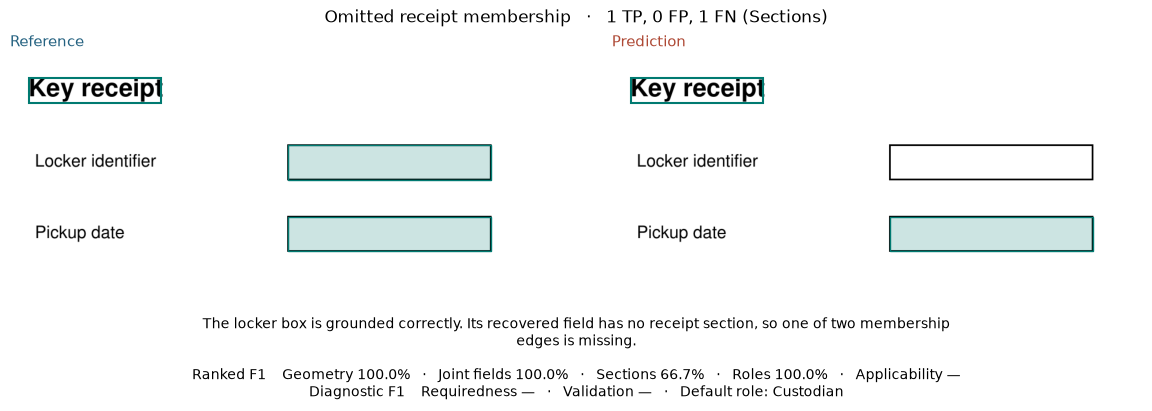

Spec group,Reference (GT),Prediction
■ fields,"{ ""locker"": { ""label"": ""Locker identifier"", ""section"": ""receipt"", ""evidenceIds"": [""locker_label""], ""regions"": [""locker_box""], ""type"": ""text"", ""options"": {} } }","{ ""slot"": { ""label"": ""Locker identifier"", ""section"": null, ""evidenceIds"": [""locker_label""], ""regions"": [""locker_box""], ""type"": ""text"", ""options"": {} } }"


### Cached Gemini 3.5 Flash-Lite

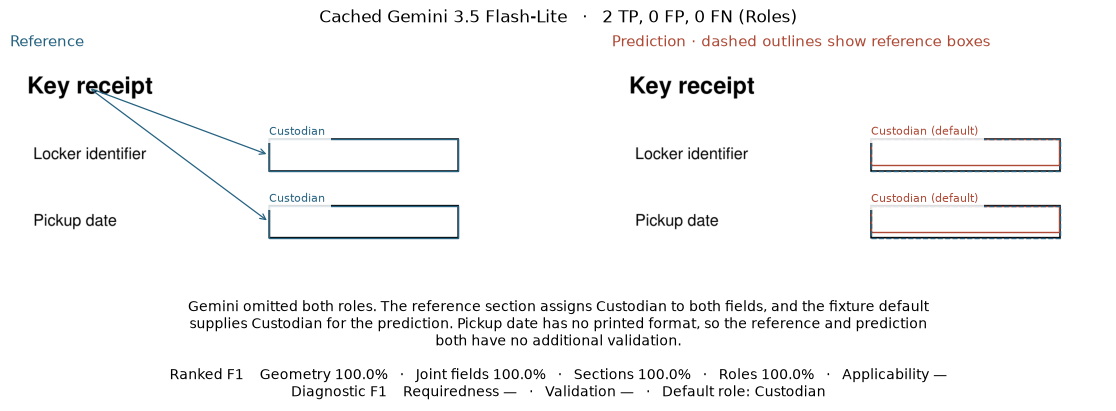

**Matched boxes on page 2**  
PDF points in x, y, width, height order.

| Reference region | Reference box | Predicted box | IoU |
|---|---|---|---:|
| `locker_box` | 190 · 76 · 130 · 22 | 190.08 · 75.9 · 128.92 · 18 | 80.3% |
| `date_box` | 190 · 122 · 130 · 22 | 190.08 · 122.1 · 128.92 · 18 | 81.1% |

| Track A | Component | TP | FP | FN | F1 |
|---|---|---:|---:|---:|---:|
| Ranked | Geometry | 2 | 0 | 0 | 100.0% |
| Ranked | Joint fields | 2 | 0 | 0 | 100.0% |
| Ranked | Sections | 2 | 0 | 0 | 100.0% |
| Ranked | Roles | 2 | 0 | 0 | 100.0% |
| Ranked | Applicability | 0 | 0 | 0 | No support |
| Diagnostic | Field type | 2 | 0 | 0 | 100.0% |
| Diagnostic | Field label | 2 | 0 | 0 | 100.0% |
| Diagnostic | Option ownership | 2 | 0 | 0 | 100.0% |
| Diagnostic | Cardinality | 2 | 0 | 0 | 100.0% |
| Diagnostic | Validation | 0 | 0 | 0 | No support |
| Diagnostic | Requiredness | 0 | 0 | 0 | No support |

Role F1 without a default 0.0%  ·  with Custodian as default 100.0%


Spec group,Reference (GT),Prediction
■ schemaVersion,"""pilot-2""","""pilot-1"""
■ sections,"{ ""receipt"": { ""title"": ""Key receipt"", ""evidenceIds"": [""heading""], ""role"": ""Custodian"" } }","{ ""key_receipt"": { ""title"": ""Key receipt"", ""evidenceIds"": [""ev_key_receipt""], ""role"": null, ""parent"": null } }"
■ fields,"{ ""locker"": { ""label"": ""Locker identifier"", ""section"": ""receipt"", ""evidenceIds"": [""locker_label""], ""regions"": [""locker_box""], ""type"": ""text"", ""options"": {} }, ""pickup"": { ""label"": ""Pickup date"", ""section"": ""receipt"", ""evidenceIds"": [""date_label""], ""regions"": [""date_box""], ""type"": ""date"", ""options"": {} } }","{ ""locker_identifier"": { ""label"": ""Locker identifier"", ""section"": ""key_receipt"", ""role"": null, ""evidenceIds"": [""ev_locker_identifier""], ""regions"": [""reg_locker_identifier""], ""type"": ""text"", ""options"": {} }, ""pickup_date"": { ""label"": ""Pickup date"", ""section"": ""key_receipt"", ""role"": null, ""evidenceIds"": [""ev_pickup_date""], ""regions"": [""reg_pickup_date""], ""type"": ""date"", ""options"": {} } }"
■ regions,"{ ""locker_box"": {""page"": 2, ""bbox"": [190.0, 76.0, 130.0, 22.0]}, ""date_box"": {""page"": 2, ""bbox"": [190.0, 122.0, 130.0, 22.0]} }","{ ""reg_locker_identifier"": {""page"": 2, ""bbox"": [190.08, 75.9, 128.92, 18.0]}, ""reg_pickup_date"": {""page"": 2, ""bbox"": [190.08, 122.1, 128.92, 18.0]} }"
■ evidence,"{ ""heading"": {""page"": 2, ""bbox"": [24.0, 33.0, 85.0, 16.0]}, ""locker_label"": {""page"": 2, ""bbox"": [28.0, 82.0, 80.0, 11.0]}, ""date_label"": {""page"": 2, ""bbox"": [28.0, 128.0, 60.0, 11.0]} }","{ ""ev_key_receipt"": {""page"": 2, ""bbox"": [25.08, 37.5, 84.04, 11.7]}, ""ev_locker_identifier"": {""page"": 2, ""bbox"": [27.72, 78.3, 79.2, 6.9]}, ""ev_pickup_date"": {""page"": 2, ""bbox"": [27.72, 124.8, 57.64, 6.9]} }"


**Track A error matrix**

| Flag | Omitted receipt membership | Cached Gemini 3.5 Flash-Lite |
| --- | --- | --- |
| Geometry | 0 | 0 |
| Joint fields | 0 | 0 |
| Sections | 1 | 0 |
| Roles | 0 | 0 |
| Applicability | 0 | 0 |
| Field type | 0 | 0 |
| Field label | 0 | 0 |
| Option ownership | 0 | 0 |
| Cardinality | 0 | 0 |
| Requiredness | 0 | 0 |
| Validation | 0 | 0 |

In [5]:
from globalforms.metrics import TrackAFlag
from globalforms.notebook_review import show_flag_matrix, show_track_a

for name, review in reviews.items():
    display(Markdown(f"### {name} · Track A"))
    flags = show_track_a(review, *pages[name], Path("output") / name / "track-a")
    if flags:
        display(Markdown("**Track A error matrix**"))
        show_flag_matrix(TrackAFlag, flags)
    else:
        print("This fixture has no Track A comparisons.")

## Track B scoring

After grounding-based alignment in B-end-to-end, each correct expected value or input status earns one point. Answer accuracy divides this count by expected fields plus entries in inactive or unmatched fields. When the reference marks an applicable answer as missing, either an omitted key or an explicit missing status earns credit. An omitted supplied answer or an incorrect answer earns zero points. A case passes only when every expected answer is correct and there are no extra entries. Each mode ranks by complete-case success rate, then answer accuracy. Coverage, active-field accuracy and inactive-entry rate remain diagnostics. Coverage measures explicit entries. Active-field accuracy also credits accepted omissions.

Teal shows expected entries. Purple shows submitted entries at their predicted positions. Bracketed text denotes a reference or submitted input status.

In the error matrix below each fixture, each column is one filled-form comparison. A 1 means the event occurred at least once. Flags may overlap. The observation rows explain why two identical blanks can score differently and why both kinds of unknown entry receive the same penalty. Accuracy uses the underlying counts.

### incident · Track B

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


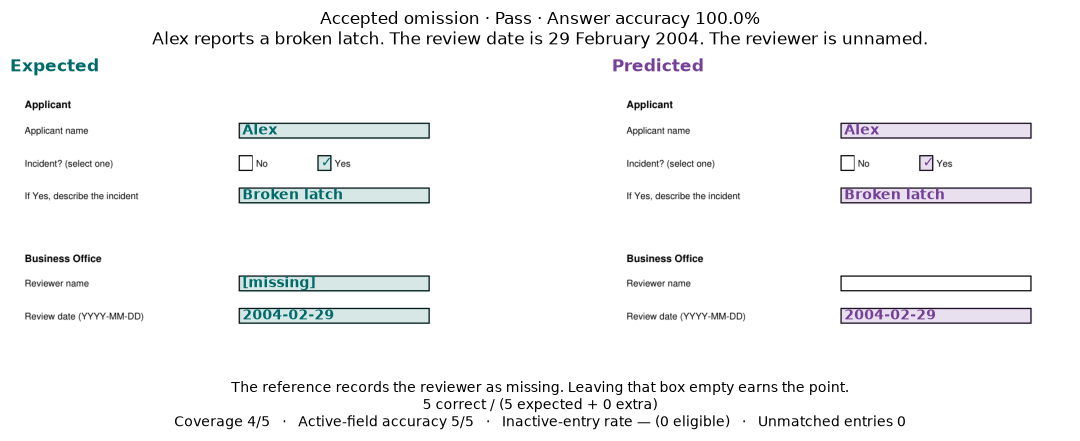

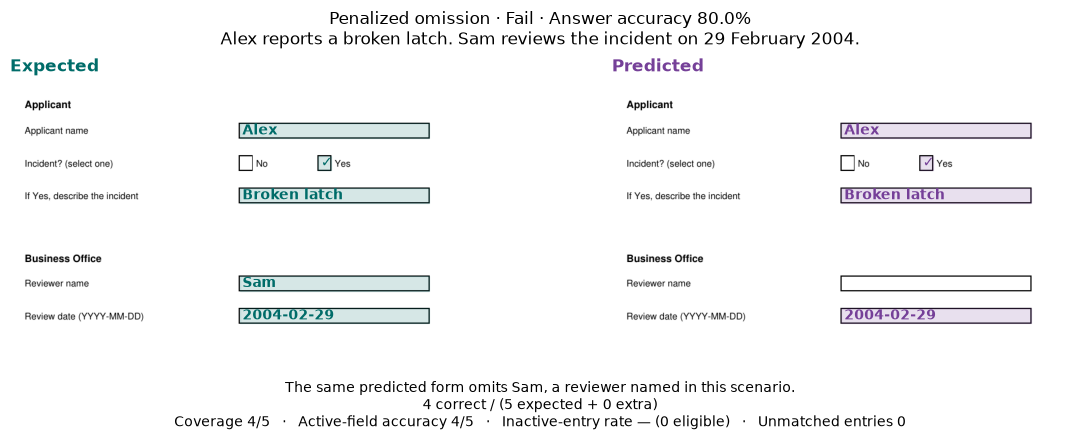

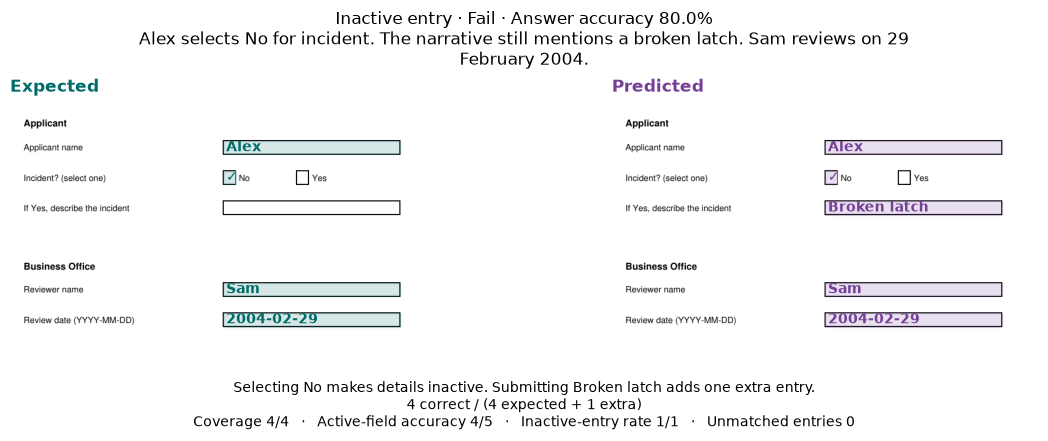

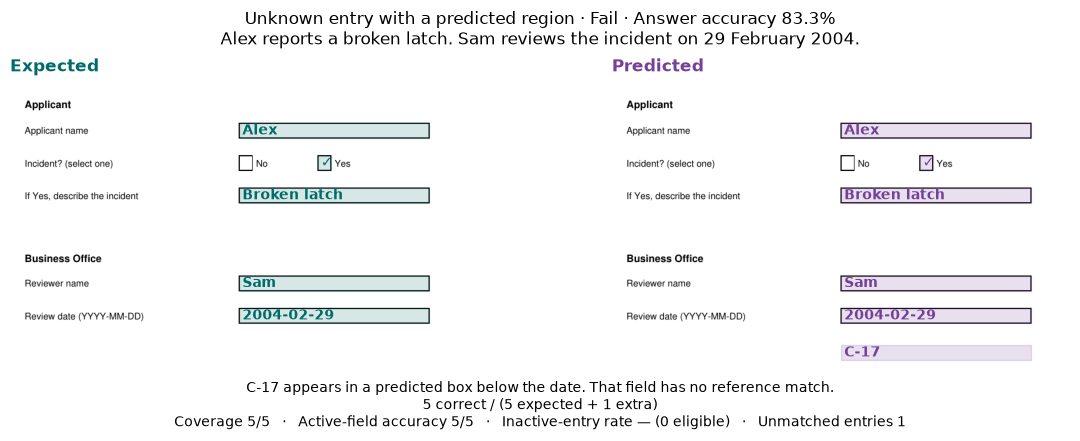

Spec group,Reference (GT),Prediction
■ fields,{},"{ ""case_number"": { ""label"": ""Case number"", ""section"": null, ""evidenceIds"": [""case_number""], ""regions"": [""case_number_0""], ""type"": ""text"", ""options"": {} } }"
■ regions,{},"{ ""case_number_0"": {""page"": 1, ""bbox"": [280.0, 325.0, 205.0, 16.0]} }"
■ evidence,{},"{ ""case_number"": {""page"": 1, ""bbox"": [48.0, 325.0, 215.0, 16.0]} }"


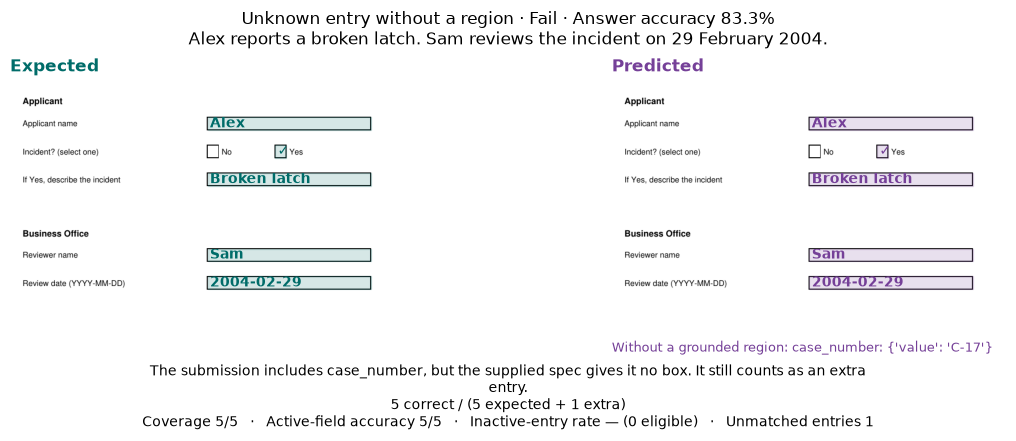

**Track B error matrix**

| Flag | Accepted omission | Penalized omission | Inactive entry | Unknown entry with a predicted region | Unknown entry without a region |
| --- | --- | --- | --- | --- | --- |
| Omitted a supplied answer | 0 | 1 | 0 | 0 | 0 |
| Filled an inactive field | 0 | 0 | 1 | 0 | 0 |
| Submitted an unknown field | 0 | 0 | 0 | 1 | 1 |
| Any scoring error | 0 | 1 | 1 | 1 | 1 |
| Left an expected field blank (observation) | 1 | 1 | 0 | 0 | 0 |
| Unknown entry has a drawable box (observation) | 0 | 0 | 0 | 1 | 0 |
| Answer accuracy | 5/5 | 4/5 | 4/5 | 5/6 | 5/6 |

### length · Track B

This fixture has no Track B scenarios.


### locker · Track B

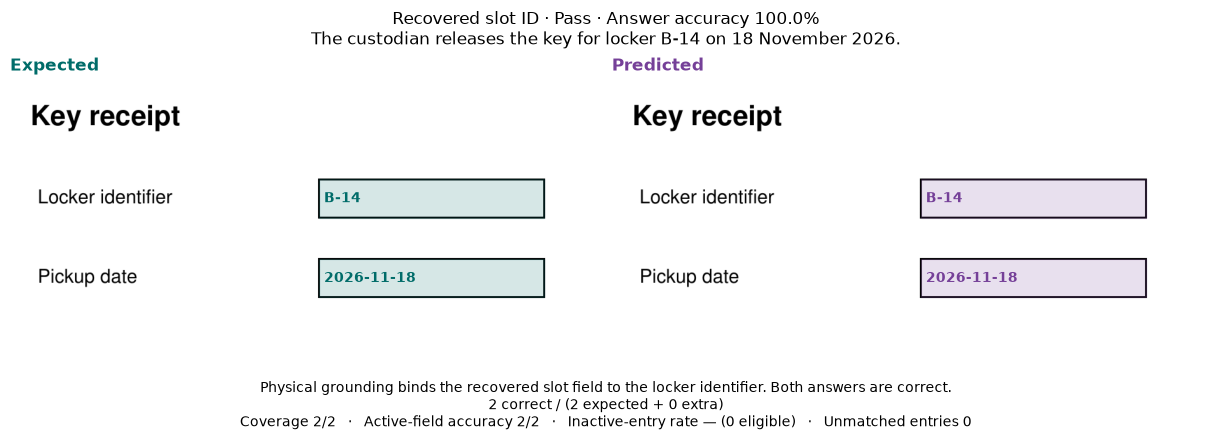

Spec group,Reference (GT),Prediction
■ fields,"{ ""locker"": { ""label"": ""Locker identifier"", ""section"": ""receipt"", ""evidenceIds"": [""locker_label""], ""regions"": [""locker_box""], ""type"": ""text"", ""options"": {} } }","{ ""slot"": { ""label"": ""Locker identifier"", ""section"": null, ""evidenceIds"": [""locker_label""], ""regions"": [""locker_box""], ""type"": ""text"", ""options"": {} } }"


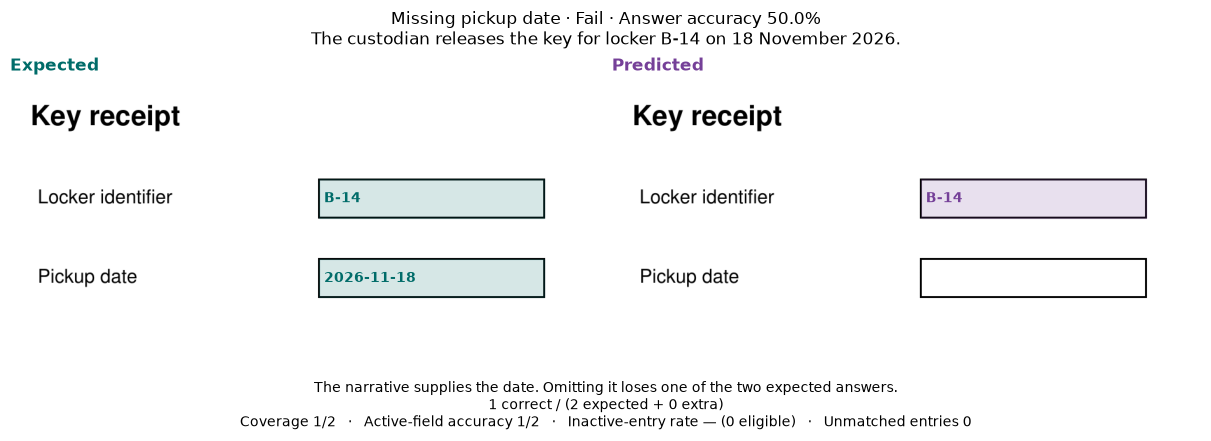

**Track B error matrix**

| Flag | Recovered slot ID | Missing pickup date |
| --- | --- | --- |
| Omitted a supplied answer | 0 | 1 |
| Filled an inactive field | 0 | 0 |
| Submitted an unknown field | 0 | 0 |
| Any scoring error | 0 | 1 |
| Left an expected field blank (observation) | 0 | 1 |
| Unknown entry has a drawable box (observation) | 0 | 0 |
| Answer accuracy | 2/2 | 1/2 |

In [6]:
from globalforms.metrics import TrackBFlag
from globalforms.notebook_review import show_track_b

for name, review in reviews.items():
    display(Markdown(f"### {name} · Track B"))
    flags, accuracies = show_track_b(review, *pages[name], Path("output") / name / "track-b")
    if flags:
        display(Markdown("**Track B error matrix**"))
        show_flag_matrix(TrackBFlag, flags, accuracy=accuracies)
    else:
        print("This fixture has no Track B scenarios.")

## Where the metrics may disagree with reviewers

| Comparison | Expected metric response | Human judgment to collect |
|---|---|---|
| Exact versus displaced answer box | Geometry, joint fields and downstream correspondence can all fall | Can a person still tell where to write? Could downstream use place an answer correctly? |
| Identical boxes, swapped option ownership | Geometry ties, joint fields falls | Would either wrong mapping make the form unusable? |
| Correct memberships, swapped section titles | Current section component ties | Does the task require correct section identity as conveyed to an agent or reviewer? |
| Inherited office role versus per-field office roles | Track A ties | Are the responsibilities identical? |
| Equivalent Yes / not-No rule | Track A ties when unanswered is undetermined in both | Would the same follow-up be asked when the choice is missing? |
| Missing calendar constraint | Ranked Track A ties, constraint diagnostic drops, B can accept an invalid answer and fail the case | Is successful recovery adequate for safe completion? |
| Correct expected values plus inactive-field leakage or extra entry | B answer accuracy falls and the case fails | How severe is entering the extra information? |
| Wrong destination with full coverage | B coverage and active-field accuracy tie, answer accuracy falls and the case fails | Would this be detected in review and how costly is it? |

These tests establish behavior on planted errors. Human alignment requires independent judgments. Before showing scores, have two reviewers compare shuffled prediction pairs for recoverability (A) and readiness to submit (B). Record better / tie, critical error yes/no, implicated field or rule and rationale. Report raw agreement between reviewers, then metric agreement and tie/reversal counts against adjudicated judgments, with raw denominators and examples. Include clean, perturbed and actual model outputs. Compare component diagnostics separately before testing candidate Track A weights. For B, compare complete success first and answer accuracy as the tie-break. Review any critical error rewarded as a tie or a win; use examples to decide whether to change scoring or keep a diagnostic.

## Smallest real-file pilot

1. **Freeze inputs.** Start with roughly five user-supplied PDFs spanning one plain form, grouped fields, a second role, explicit validation and a conditional branch. One form can cover multiple features. Store PDF SHA-256, source URL if available, annotation version and page coordinates. Include one confirmed-negative rule example.
2. **Author the reference independently.** Annotate JSON plus evidence rectangles or text spans. A second reviewer checks every page and distinguishes explicit, inferred and unresolved logic. Keep unresolved items out of ranked decisions until their treatment is defined. Write paired scenario narratives for the same forms, including missing and conflicting input. Keep each pair to one changed fact.
3. **Run one predictor through a thin adapter.** Entry points are `predict_spec(pdf) -> JSON` and `complete(spec, narrative) -> JSON`. Render page images for one vision-capable model such as Qwen, ask for schema-constrained output, and convert coordinates back to PDF points. Save raw JSON, parse failures and model settings. If reusing the PDF forms compiler or forms-agent repo, first check which entry point already yields regions, field labels or widgets; adapt that output to the same contract. Measure absent properties instead of copying them from the reference. The review runs use recorded fixture submissions. Independent model outputs can be supplied through the same manifest.
4. **Validate output before scoring.** Implement small structural checks for unique IDs, finite positive rectangles, known pages, ownership and option links, acyclic section parents, valid targets and evidence pointers. Log malformed or failed submissions and keep them in metric denominators. For completion, run the same narratives once with reference specs and once with recovered specs; preserve raw submitted IDs until evaluation binds them.
5. **Review divergences.** Pool counts across documents and scenarios before computing scores. Add document-macro diagnostics on positive support and report confirmed-negative hallucinations plus support. Compare reviewer judgments with component scores, B success and paired passes. Keep the gold specs, raw predictions, score rows and reviewer decisions as separate files so metric changes can be replayed. Pin eligibility, matching and weights only after reviewing disagreement cases.

**Pilot exit check.** A model can emit a valid, reviewable spec from the supplied PDF alone; both B modes score from the same independently reviewed scenarios; every planted failure has an explained metric response; and remaining human/metric disagreements have a recorded scoring decision.

### Scope of the pilot

Component counts are pooled before computing F1. A score without support is displayed as a dash. The pilot leaves the weighted Track A headline open. Track B expects resolved branches, ISO dates and reviewed expected entries. Broader value normalization, split/merge alignment, unresolved branch scoring and failed-submission policies remain open. See the README for fixture input contracts and the standalone historical regression checks.